In [53]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.integrate import solve_ivp
from PIL import Image
import buchineri as buchineri
import importlib
importlib.reload(buchineri)
from buchineri import schwarzschild
from buchineri import immagine
from buchineri import kerr

f1="milkyway16k.png"
f2="griglia.png"



plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 11,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

# Schwarzschild

In [2]:
#       VARIABILI       #
M=1                     # Massa 
r0=30*M                 # distanza dal buco nero
FOV=70*2*np.pi/360      # field of view
N=5000                  # numero di pixel per lato dell'immagine PARI
#########################
phi_pixel_sch,black_sch=schwarzschild(M,r0,FOV,N)


b_c numerico = 5.1961524226 M,  teorico = 5.1961524227 M


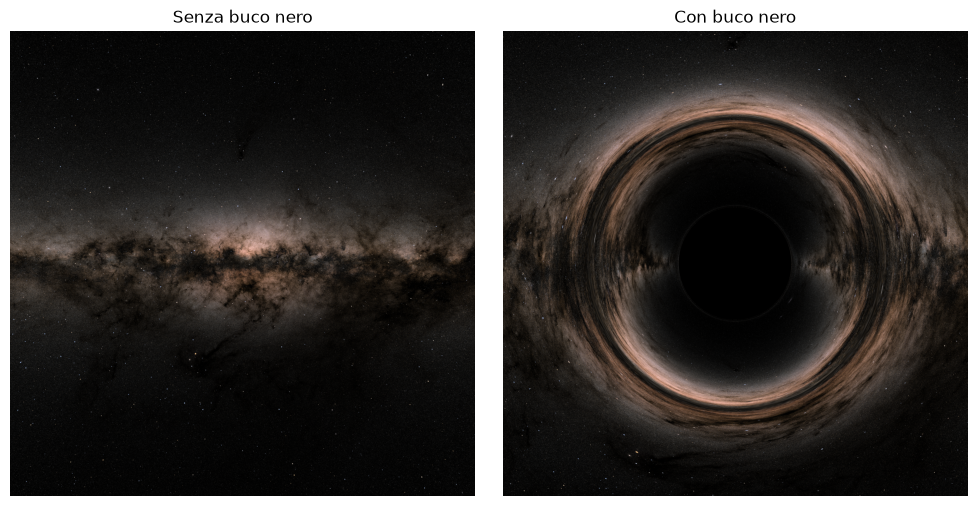

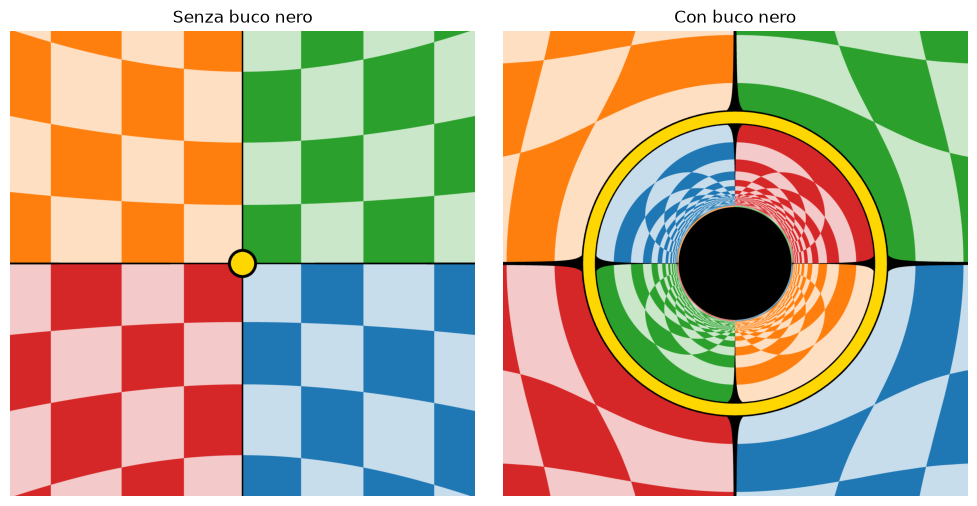

In [3]:
imgvuoto_sch1,imgbuco_sch1=immagine(f1,phi_pixel_sch ,black_sch,FOV,N)
Image.MAX_IMAGE_PIXELS = None   # il 16k supera la soglia di PIL
Image.fromarray((imgbuco_sch1[::-1] * 255 + 0.5).astype(np.uint8)).save(f"schw_{f1}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
Image.fromarray((imgvuoto_sch1[::-1] * 255 + 0.5).astype(np.uint8)).save(f"vuoto_schw_{f1}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
imgvuoto_sch2,imgbuco_sch2=immagine(f2,phi_pixel_sch ,black_sch,FOV,N)
Image.fromarray((imgbuco_sch2[::-1] * 255 + 0.5).astype(np.uint8)).save(f"schw_{f2}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
Image.fromarray((imgvuoto_sch2[::-1] * 255 + 0.5).astype(np.uint8)).save(f"vuoto_schw_{f2}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")

## Validazione schwarzschild

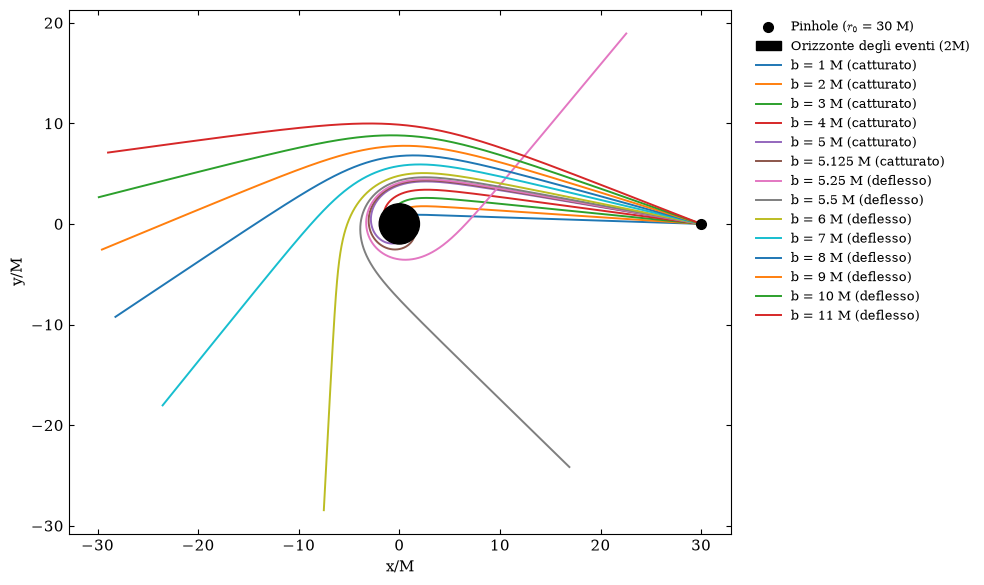

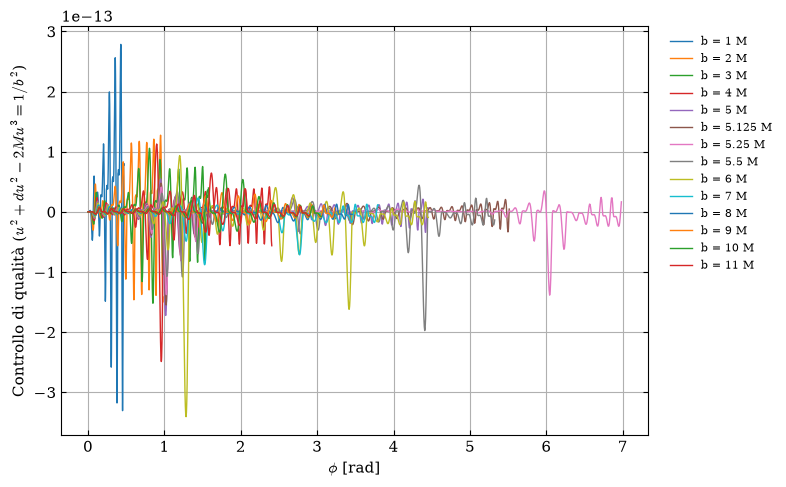

In [67]:
from buchineri import integratore_schwarzschild

def conversione_polari_schw(phi,u):
    # Converte la soluzione u(phi) in coordinate cartesiane per il plot
    r=1/u
    return r*np.cos(phi), r*np.sin(phi)

r0 = 30 * M
b_values = [1,2,3,4,5,5.125,5.25,5.5,6, 7, 8,9,10,11]

# figura 1
fig1, ax1 = plt.subplots(figsize=(10, 10))
cerchio = plt.Circle((0, 0), 2 * M, color='black', label='Orizzonte degli eventi (2M)')
ax1.plot(r0, 0, marker='o', color='black', markersize=7, linestyle='none',
         zorder=11, label=f'Pinhole ($r_0$ = {r0/M:g} M)')
ax1.add_patch(cerchio)
ax1.set_aspect('equal') 
ax1.set_xlabel('x/M')
ax1.set_ylabel('y/M')

# figura 2
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.set_xlabel('$\\phi$ [rad]')
ax2.set_ylabel('Controllo di qualità ($u^2 + du^2 - 2Mu^3=1/b^2$)')
ax2.grid(True)

# integrazione
risultati = []
for b in b_values:
    sol, catturato, _ = integratore_schwarzschild(b, r0,M)
    risultati.append((b, sol, catturato))

b_catt = [b for b, _, c in risultati if c]
b_defl = [b for b, _, c in risultati if not c]

# Plotting
for b, sol, catturato in risultati:
    phi = np.linspace(0,sol.t[-1], 1000)
    u, du = sol.sol(phi)
    mask =u>(1/(r0+1e-6))  
    phi = phi[mask]
    u = u[mask]
    du = du[mask]
    x, y = conversione_polari_schw(phi, u)
    stato = 'catturato' if catturato else 'deflesso'
    ax1.plot(x, y, linewidth=1.4, label=f'b = {b:g} M ({stato})')
    controllo = u**2 + du**2 - 2*M*u**3 - 1/b**2
    ax2.plot(phi, controllo, linewidth=1, label=f'b = {b:g} M')

# orizzonte sopra le traiettorie, così le curve catturate "entrano" nel disco nero
cerchio.set_zorder(10)

# legenda fuori dal grafico, per non coprire le traiettorie
ax1.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9, frameon=False)
ax2.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8, frameon=False)
fig1.tight_layout()
fig2.tight_layout()

plt.show()

# Kerr

In [ ]:
#       VARIABILI       #
M=1                     # Massa 
a=0.99                  # Spin
r0=30*M                 # distanza dal buco nero
th0=np.pi/2             # angolo iniziale
FOV=70*2*np.pi/360      # field of view
N=1000                  # numero di pixel per lato dell'immagine (N=1000 -> 152 minuti)
#########################
import subprocess, os

caff = subprocess.Popen(["caffeinate", "-i", "-w", str(os.getpid())])
try:
    phi_pixel_kerr,th_pixel,black_kerr=kerr(M,a,r0,th0,FOV,N)
    pass
finally:
    caff.terminate()
np.savez("kerr_data.npz", phi_pixel_kerr=phi_pixel_kerr, th_pixel=th_pixel, black_kerr=black_kerr)


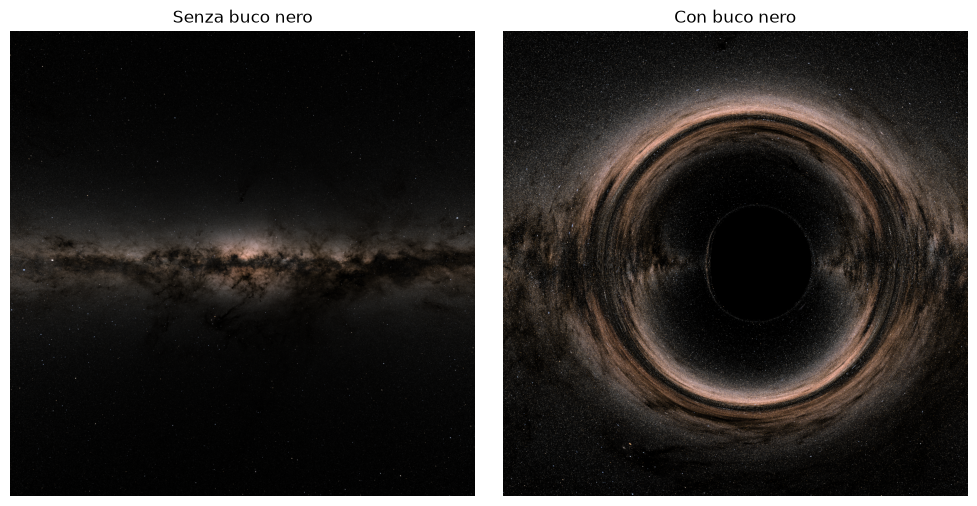

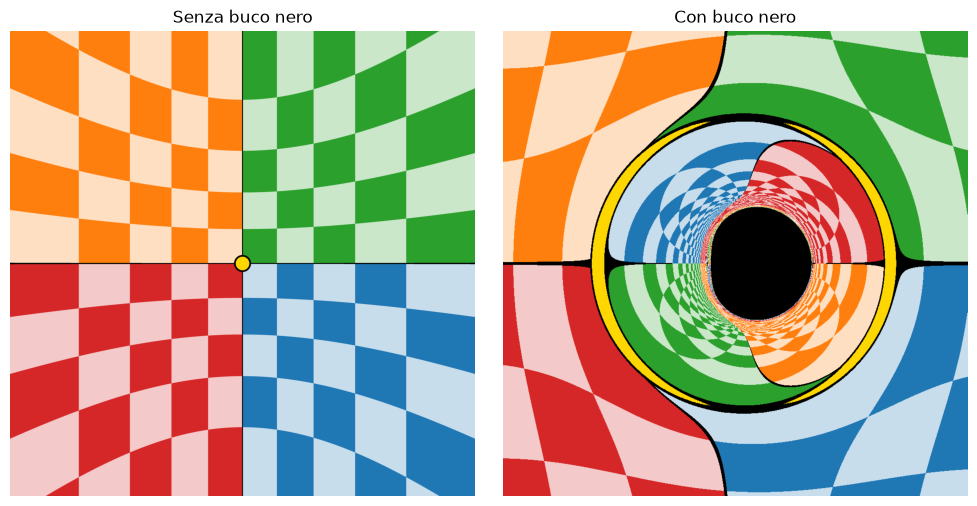

In [10]:
data = np.load("kerr_data.npz")
phi_pixel_kerr = data["phi_pixel_kerr"]
th_pixel = data["th_pixel"]
black_kerr = data["black_kerr"]

imgvuoto_kerr1,imgbuco_kerr1=immagine(f1,phi_pixel_kerr ,black_kerr,FOV,N,th_pixel)
Image.MAX_IMAGE_PIXELS = None   # il 16k supera la soglia di PIL
Image.fromarray((imgbuco_kerr1[::-1] * 255 + 0.5).astype(np.uint8)).save(f"kerr_{f1}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")
imgvuoto_kerr2,imgbuco_kerr2=immagine(f2,phi_pixel_kerr ,black_kerr,FOV,N,th_pixel)
Image.fromarray((imgbuco_kerr2[::-1] * 255 + 0.5).astype(np.uint8)).save(f"kerr_{f2}_N={N}_r0={r0}_FOV={FOV*360/(2*np.pi)}°.png")

## Validazione Kerr

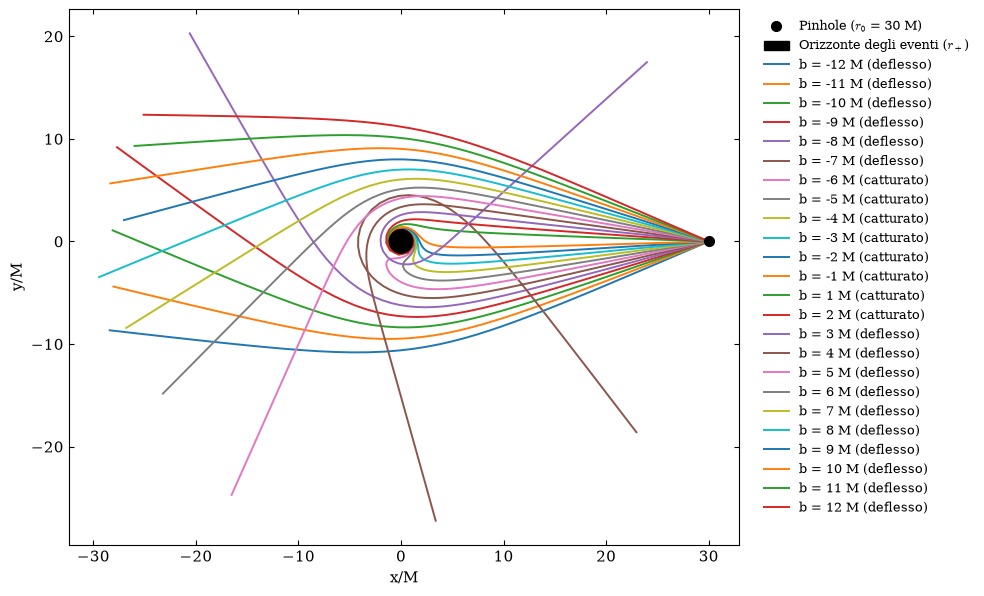

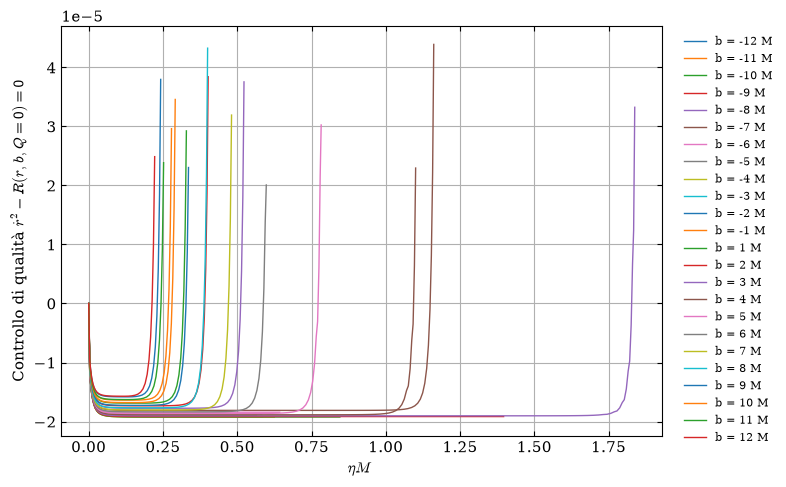

In [69]:
from buchineri import integratore_kerr

def conversione_polari_kerr(phi,r):
    return r*np.cos(phi), r*np.sin(phi)

a=0.99
r0 = 30 * M
th0 = np.pi/2

b_values = [-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,1,2,3,4,5,6,7,8,9,10,11,12]

# figura 1
fig1, ax1 = plt.subplots(figsize=(10, 10))
cerchio = plt.Circle((0, 0), M+np.sqrt(M**2-a**2), color='black', label='Orizzonte degli eventi ($r_+$)')
ax1.plot(r0, 0, marker='o', color='black', markersize=7, linestyle='none',
         zorder=11, label=f'Pinhole ($r_0$ = {r0/M:g} M)')
ax1.add_patch(cerchio)
ax1.set_aspect('equal') 
ax1.set_xlabel('x/M')
ax1.set_ylabel('y/M')

# figura 2
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax2.set_xlabel('$\\eta M$ ')
ax2.set_ylabel('Controllo di qualità $\\dot r^2-R(r,b,Q=0)=0$')
ax2.grid(True)

# integrazione
risultati = []
for b in b_values:
    sol, catturato, _,_ = integratore_kerr(b,0, r0,th0,1,M,a)
    risultati.append((b, sol, catturato))

b_catt = [b for b, _, c in risultati if c]
b_defl = [b for b, _, c in risultati if not c]

from buchineri import R
# Plotting
for b, sol, catturato in risultati:
    tau=sol.t
    r, phi, _, dr, _ = sol.y
    mask =r<(r0+1e-6) 
    r = r[mask]
    dr = dr[mask]
    phi = phi[mask]
    tau = tau[mask]
    x, y = conversione_polari_kerr(phi, r)
    stato = 'catturato' if catturato else 'deflesso'
    ax1.plot(x, y, linewidth=1.4, label=f'b = {b:g} M ({stato})')
    controllo = (dr**2-R(r,b,0,M,a))
    ax2.plot(tau, controllo, linewidth=1, label=f'b = {b:g} M')

# orizzonte sopra le traiettorie, così le curve catturate "entrano" nel disco nero
cerchio.set_zorder(10)

# legenda fuori dal grafico, per non coprire le traiettorie
ax1.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9, frameon=False)
ax2.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8, frameon=False)
fig1.tight_layout()
fig2.tight_layout()

plt.show()

## Bisezione per trovare $b_+$ e $b_-$ sul piano equatoriale

confronto |b| critico prograde e retrograde con a=0 e valore esatto da Schwarzschild: 5.19615182466805 5.19615182466805 5.196152422706632
b_critico per a=0.99:  2.2516468428075314 -6.983323239721358


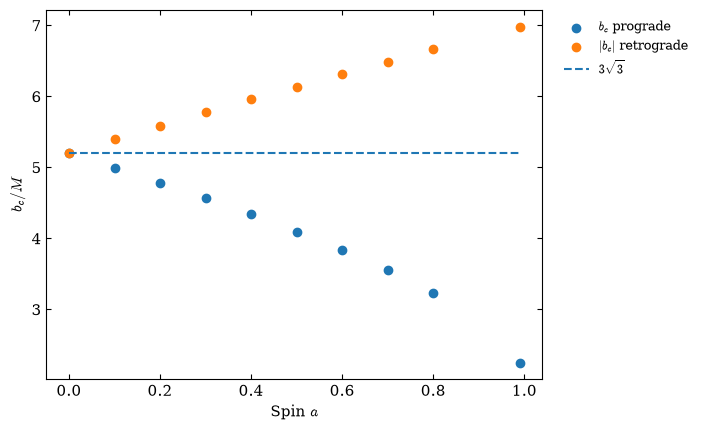

In [56]:
r0=30*M
def catturato_kerr(a,b):
    _, cat, _,_ = integratore_kerr(b,0, r0,th0,1,M,a)
    return cat

def bcriticoKerr (a,plus_or_minus):
    if(plus_or_minus):
        lo, hi = 2.0*M, 7.0*M          
    else:    
        lo,hi=-2.0*M,-7.0*M
    # bisezione per calcolare b_c
    for _ in range(30):               
        mid=0.5*(lo + hi)
        if catturato_kerr(a,mid): 
            lo = mid
        else:        
            hi = mid
    return lo/M
b_plus=[]
b_minus=[]
list_a=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.99]
for a in list_a:
    b_plus.append(bcriticoKerr(a,1))
    b_minus.append(bcriticoKerr(a,0))
plt.scatter(list_a,b_plus, label='$b_c$ prograde')
plt.scatter(list_a,-1*np.array(b_minus), label='$|b_c|$ retrograde')
plt.plot(list_a,3*np.sqrt(3)*M*np.ones(len(list_a)),'--',label='$3\\sqrt{3}$')
plt.xlabel('Spin $a$')
plt.ylabel('$b_c/M$')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9, frameon=False)
# validazione con schwarzschild:
print("confronto |b| critico prograde e retrograde con a=0 e valore esatto da Schwarzschild:", b_plus[0], -1*b_minus[0], 3*np.sqrt(3)*M)
print("b_critico per a=0.99: ",b_plus[-1],b_minus[-1])